# Monitoramento e antecipação de risco hídrico — Sistema Cantareira (RMSP)

**Global Solution 2026.2 · Data Science and Analytics · FIAP**

**Integrantes:** João Victor Alves de Abreu (RM 564946) e Rodrigo Kenshin Viana Matayoshi (RM 564026).

Notebook reproduzível com dados reais e públicos da Sabesp (01/01/2024 a 07/11/2026). Estrutura:

1. Problema, público e pergunta de pesquisa
2. Fonte, qualidade e tratamento dos dados
3. Análise exploratória (EDA)
4. Indicadores hídricos
5. Modelagem: regressão do volume e classificação de piora de faixa (validação *walk-forward*)
6. Critérios de alerta e situação atual
7. Conclusões e recomendações
8. Limitações, responsabilidade e reprodutibilidade

## 1. Problema, público e pergunta de pesquisa

O Sistema Cantareira é o maior produtor de água da Região Metropolitana de São Paulo. A retirada de água é regulada por **faixas de operação** definidas pela Resolução Conjunta ANA/DAEE nº 925/2017, em função do volume útil armazenado: quanto menor a faixa, menor a vazão que pode ser retirada. Mudanças de faixa, portanto, têm consequência direta no abastecimento.

**Público apoiado:** equipes técnicas de gestão de recursos hídricos (operador, agência reguladora, defesa civil e comitês de bacia), que precisam de tempo para preparar medidas preventivas.

**Decisão apoiada:** *intensificar o monitoramento e preparar medidas antes que o sistema mude de faixa* — e não decidir racionamento. Toda saída deste notebook é uma recomendação para avaliação humana.

**Pergunta de pesquisa:** *com dados publicados até o dia t (volume, chuva e vazões), é possível sinalizar com até 30 dias de antecedência que o Cantareira vai entrar em uma faixa de operação mais restritiva?*

Perguntas auxiliares:
- Quais condições hidrológicas (estação do ano, chuva acumulada, balanço entre afluência e retirada) estão associadas às quedas de volume?
- Modelos de aprendizado de máquina estimam o volume futuro melhor do que referências simples (persistência e extrapolação de tendência)?

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (confusion_matrix, fbeta_score, mean_absolute_error,
                             mean_squared_error, precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import hydro

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
CORES_FAIXA = {1: "#2e7d32", 2: "#f9a825", 3: "#ef6c00", 4: "#c62828", 5: "#6a1b9a"}
CORES_NIVEL = ["#2e7d32", "#f9a825", "#ef6c00", "#c62828"]
SEED = 42

df = hydro.load_series(ROOT / "data" / "cantareira_diario_2024_2026.csv")
print(f"{len(df)} dias de {df.date.min():%d/%m/%Y} a {df.date.max():%d/%m/%Y}")
df.head()

1042 dias de 01/01/2024 a 07/11/2026


,date,system,storage_pct,rain_mm,natural_inflow_m3s,produced_flow_m3s
0,2024-01-01,Cantareira,71.40,0.00,10.92,24.39
1,2024-01-02,Cantareira,71.19,0.00,9.06,27.37
2,2024-01-03,Cantareira,71.01,3.05,15.65,27.87
3,2024-01-04,Cantareira,71.14,18.00,49.86,27.53
4,2024-01-05,Cantareira,71.14,0.20,30.92,28.73


## 2. Fonte, qualidade e tratamento dos dados

| Item | Descrição |
|---|---|
| Fonte | Portal dos Mananciais — Sabesp (`mananciais.sabesp.com.br/base-dados`) |
| Acesso | Endpoint usado pelo próprio portal: `/api/v4/sistemas/64/dados/diario/{início}/{fim}` (ID 64 = Cantareira). Não é uma API documentada; pode mudar sem aviso. |
| Período | 01/01/2024 a 07/11/2026 (1.042 dias). O dia 08/11/2026 foi excluído por ainda ser provisório. |
| Frequência | Diária, publicada pelo portal. |
| Variáveis | `volumeUtilArmazenadoPorcentagem` (% do volume útil), `chuva` (mm/dia, média dos postos do sistema), `vazaoNatural` (afluência natural, m³/s) e `vazaoProduzida` (água produzida para abastecimento, m³/s). |
| Extração | Consulta mês a mês em 08/11/2026; arquivos mensais em `data/raw/monthly/` e série consolidada em `data/cantareira_diario_2024_2026.csv`. |
| Controle | O trecho 2024–2025 foi comparado com estatísticas de uma extração anterior (05/11/2026, arquivo bruto com SHA-256 registrado em `docs/DATA_SOURCE.md`): número de linhas, mínimo, máximo, mediana, chuva total e dias sem chuva coincidiram exatamente. |
| Limitações | Um único sistema produtor; sem vazão de jusante (liberada para a bacia PCJ); chuva é média de postos, não distribuição espacial; termos explícitos de redistribuição não foram localizados — dados usados para fins acadêmicos, com atribuição à Sabesp. |

Não há dados pessoais: todas as variáveis descrevem o reservatório.

In [2]:
# Verificação de qualidade: lacunas, duplicidades, ausentes, faixas físicas e estatísticas de controle
qualidade = {
    "linhas": len(df),
    "datas duplicadas": int(df.date.duplicated().sum()),
    "dias faltantes": int((df.date.diff().dt.days.dropna() - 1).sum()),
    "valores ausentes": int(df.isna().sum().sum()),
    "volume fora de 0–100 %": int((~df.storage_pct.between(0, 100)).sum()),
    "chuva/vazões negativas": int((df[["rain_mm", "natural_inflow_m3s", "produced_flow_m3s"]] < 0).sum().sum()),
}
print(pd.Series(qualidade).to_string())

ref = df[df.date <= "2025-12-31"]
controle = pd.DataFrame({
    "registrado em 05/11/2026": [731, 19.68, 78.12, 54.39, 2489.9, 400],
    "extração atual": [len(ref), round(ref.storage_pct.min(), 2), round(ref.storage_pct.max(), 2),
                       round(ref.storage_pct.median(), 2), round(ref.rain_mm.sum(), 1), int((ref.rain_mm == 0).sum())],
}, index=["linhas 2024–2025", "volume mínimo (%)", "volume máximo (%)", "volume mediano (%)",
          "chuva total (mm)", "dias sem chuva"])
controle["confere"] = np.isclose(controle.iloc[:, 0], controle.iloc[:, 1])
display(controle)
df.describe().T[["mean", "std", "min", "50%", "max"]].rename(
    index={"storage_pct": "volume útil (%)", "rain_mm": "chuva (mm/dia)",
           "natural_inflow_m3s": "vazão natural (m³/s)", "produced_flow_m3s": "vazão produzida (m³/s)"})

linhas                    1042
datas duplicadas             0
dias faltantes               0
valores ausentes             0
volume fora de 0–100 %       0
chuva/vazões negativas       0


,registrado em 05/11/2026,extração atual,confere
linhas 2024–2025,731.00,731.00,True
volume mínimo (%),19.68,19.68,True
volume máximo (%),78.12,78.12,True
volume mediano (%),54.39,54.39,True
chuva total (mm),2489.90,2489.90,True
dias sem chuva,400.00,400.00,True


,mean,std,min,50%,max
date,2025-06-04 12:00:00,NaN,2024-01-01 00:00:00,2025-06-04 12:00:00,2026-11-07 00:00:00
volume útil (%),48.29,15.99,19.29,46.45,78.12
chuva (mm/dia),3.7,8.3,0.0,0.0,67.3
vazão natural (m³/s),27.1,24.93,2.42,18.69,213.24
vazão produzida (m³/s),27.84,2.51,19.24,27.98,32.65


**Tratamento e rastreabilidade.** Nenhum valor foi imputado ou removido: a série não tem lacunas, duplicidades nem valores fora do intervalo físico. A única transformação foi renomear colunas e converter a data (ver `data/raw/monthly/*.csv` → `data/cantareira_diario_2024_2026.csv`).

Os saltos diários acima de 1 ponto percentual coincidem com dias de chuva forte (por exemplo, 27/12/2024 com 67 mm e 10/02/2026 com 51 mm); não há evidência de erro de medição. A célula seguinte faz uma checagem física adicional.

In [3]:
# Checagem física: variação de estoque (hm³/dia) vs. balanço afluência − produção (hm³/dia)
seg = 86400 / 1e6  # m³/s -> hm³/dia
fis = pd.DataFrame({
    "date": df.date,
    "delta_estoque_hm3": df.storage_pct.diff() / 100 * hydro.VOLUME_UTIL_TOTAL_HM3,
    "balanco_hm3": (df.natural_inflow_m3s - df.produced_flow_m3s) * seg,
}).dropna()
fis["saida_nao_medida_m3s"] = (fis.balanco_hm3 - fis.delta_estoque_hm3) / seg
r = fis[["delta_estoque_hm3", "balanco_hm3"]].corr().iloc[0, 1]
print(f"Volume útil total estimado: {hydro.VOLUME_UTIL_TOTAL_HM3:.0f} hm³")
print(f"Correlação entre variação de estoque e balanço (diária): {r:.2f}")
print("Saída não medida implícita (jusante + perdas), m³/s:")
print(fis.saida_nao_medida_m3s.describe()[["mean", "50%", "std"]].round(2).to_string())

Volume útil total estimado: 982 hm³
Correlação entre variação de estoque e balanço (diária): 0.99
Saída não medida implícita (jusante + perdas), m³/s:
mean    1.29
50%     2.01
std     4.50


A variação diária do estoque acompanha fortemente o balanço entre afluência e produção, o que confirma a coerência entre as variáveis. A diferença média (algumas unidades de m³/s) corresponde a saídas que a série não informa — principalmente a vazão liberada a jusante para a bacia PCJ e a evaporação. Por isso o balanço é tratado como **balanço parcial** nos indicadores.

## 3. Análise exploratória

Dias em cada faixa: {'Atenção': 487, 'Normal': 229, 'Alerta': 181, 'Restrição': 131, 'Especial': 14}


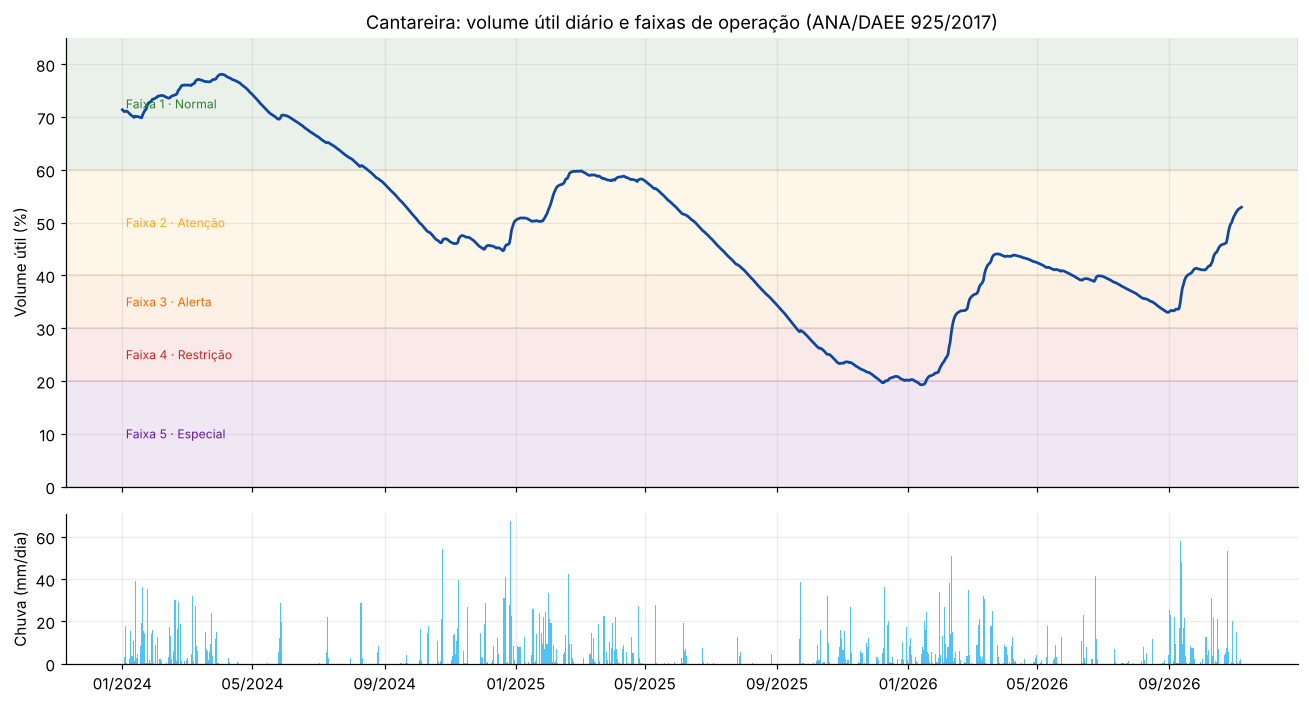

In [4]:
fig, (ax, axc) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, height_ratios=[3, 1])
for numero, nome, lim in hydro.FAIXAS:
    sup = 100 if numero == 1 else hydro.limite_inferior(numero - 1)
    ax.axhspan(lim, sup, color=CORES_FAIXA[numero], alpha=0.10)
    ax.text(df.date.min(), (lim + min(sup, 85)) / 2, f" Faixa {numero} · {nome}", va="center", fontsize=8,
            color=CORES_FAIXA[numero])
ax.plot(df.date, df.storage_pct, color="#0d47a1", lw=1.8)
ax.set(ylim=(0, 85), ylabel="Volume útil (%)", title="Cantareira: volume útil diário e faixas de operação (ANA/DAEE 925/2017)")
axc.bar(df.date, df.rain_mm, width=1, color="#4fc3f7")
axc.set(ylabel="Chuva (mm/dia)")
axc.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
fig.tight_layout(); plt.show()

faixas_dias = df.storage_pct.map(hydro.faixa).map(hydro.nome_faixa).value_counts()
print("Dias em cada faixa:", faixas_dias.to_dict())

**Leitura do gráfico.** O volume caiu de 78 % (abril/2024) para menos de 20 % (dezembro/2025 e janeiro/2026), passando por todas as faixas de operação em cerca de 20 meses. A recuperação veio com as chuvas de fevereiro–março de 2026 e de setembro–outubro de 2026. Dois padrões ficam evidentes:
- a queda é **lenta e quase linear nas estações secas** (abril a setembro), quando praticamente não chove;
- a recuperação é **abrupta**, concentrada em poucos eventos de chuva intensa.

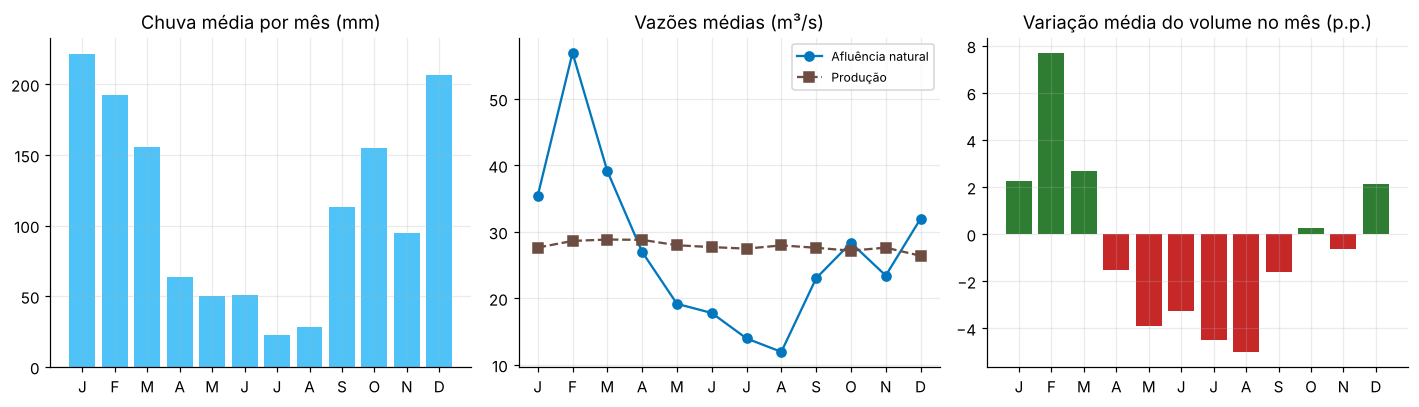

mes,1,2,3,4,5,6,7,8,9,10,11,12
chuva,221.6,192.6,155.7,63.5,50.2,51.0,22.8,28.3,113.4,154.5,94.6,206.7
afluencia,35.4,56.9,39.1,27.0,19.2,17.8,14.0,11.9,23.0,28.3,23.4,32.0
producao,27.6,28.6,28.8,28.8,28.0,27.7,27.5,27.9,27.6,27.1,27.6,26.4


In [5]:
mensal = df.assign(mes=df.date.dt.month).groupby("mes").agg(
    chuva=("rain_mm", "sum"), afluencia=("natural_inflow_m3s", "mean"), producao=("produced_flow_m3s", "mean"))
anos = df.groupby(df.date.dt.month).date.apply(lambda s: s.dt.year.nunique())
mensal["chuva"] = mensal["chuva"] / anos  # média mensal entre os anos disponíveis
var_mensal = df.set_index("date").storage_pct.resample("ME").last().diff()
var_mes = var_mensal.groupby(var_mensal.index.month).mean()

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
meses = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
axs[0].bar(mensal.index, mensal.chuva, color="#4fc3f7"); axs[0].set(title="Chuva média por mês (mm)")
axs[1].plot(mensal.index, mensal.afluencia, "o-", label="Afluência natural", color="#0277bd")
axs[1].plot(mensal.index, mensal.producao, "s--", label="Produção", color="#6d4c41")
axs[1].set(title="Vazões médias (m³/s)"); axs[1].legend(fontsize=8)
axs[2].bar(var_mes.index, var_mes.values, color=np.where(var_mes.values < 0, "#c62828", "#2e7d32"))
axs[2].set(title="Variação média do volume no mês (p.p.)")
for a in axs: a.set_xticks(range(1, 13), meses)
fig.tight_layout(); plt.show()
mensal.round(1).T

**Sazonalidade.** A afluência natural supera com folga a produção apenas de dezembro a março. De abril a setembro o sistema opera em déficit e perde de 1,5 a 5 p.p. por mês; outubro e novembro ficam perto do equilíbrio, dependendo de quando as chuvas começam. Isso significa que o volume no fim de março é o "colchão" para atravessar a estiagem — e que uma estação chuvosa fraca (como 2024/2025) se transforma em risco no segundo semestre seguinte. A produção é quase constante (≈ 25–31 m³/s): o ajuste de retirada acontece em degraus, conforme as faixas.

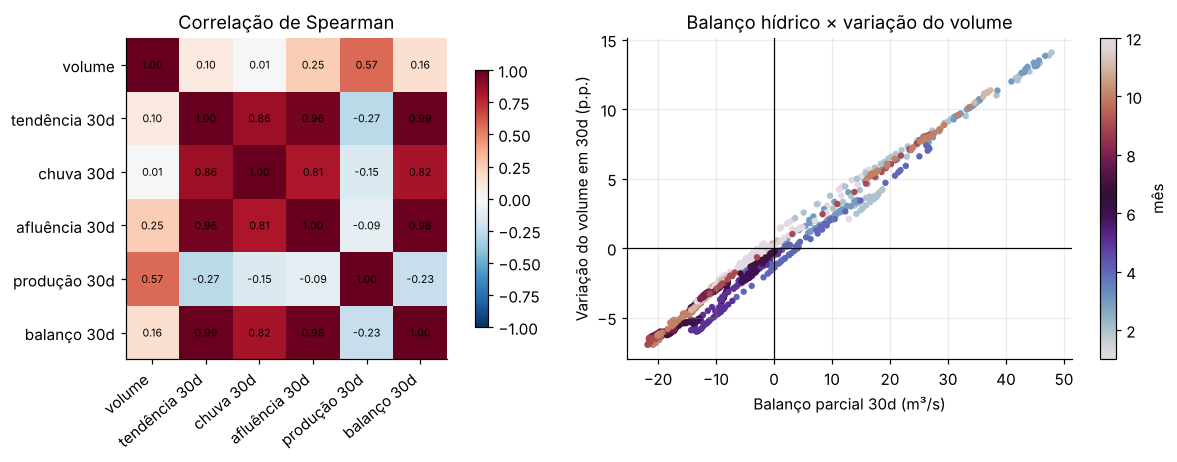

In [6]:
ind = hydro.add_indicators(df)
cols = {"storage_pct": "volume", "trend_30d": "tendência 30d", "rain_30d": "chuva 30d",
        "inflow_30d": "afluência 30d", "produced_30d": "produção 30d", "balance_30d": "balanço 30d"}
corr = ind[list(cols)].rename(columns=cols).corr(method="spearman")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3))
im = a1.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
a1.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right"); a1.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        a1.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
a1.set_title("Correlação de Spearman"); a1.grid(False); fig.colorbar(im, ax=a1, shrink=0.8)
sc = a2.scatter(ind.balance_30d, ind.trend_30d, c=ind.date.dt.month, cmap="twilight", s=10)
a2.axhline(0, color="k", lw=0.8); a2.axvline(0, color="k", lw=0.8)
a2.set(xlabel="Balanço parcial 30d (m³/s)", ylabel="Variação do volume em 30d (p.p.)",
       title="Balanço hídrico × variação do volume")
fig.colorbar(sc, ax=a2, label="mês")
fig.tight_layout(); plt.show()

**Relações.** O balanço de 30 dias e a variação do volume em 30 dias têm correlação muito alta: o reservatório responde ao que entra menos o que sai. A chuva acumulada se relaciona com a variação do volume principalmente por meio da afluência. O nível atual do volume, sozinho, diz pouco sobre a próxima variação — o que motiva indicadores de **tendência**, **balanço** e **distância até a próxima faixa**, em vez de olhar apenas a porcentagem.

## 4. Indicadores hídricos

| Indicador | Fórmula | Unidade | Periodicidade | Interpretação |
|---|---|---|---|---|
| **I1 · Volume útil e faixa** | `volumeUtil(t)`; faixa pela Resolução ANA/DAEE 925/2017 | % e faixa 1–5 | diária | Estado atual. Abaixo de 60 % a retirada passa a ser limitada. |
| **I2 · Tendência de 30 dias** | `V(t) − V(t−30)` | p.p./30 dias | diária | Negativa = consumo de estoque; quantifica a velocidade da queda. |
| **I3 · Balanço hídrico parcial** | `média30(afluência) − média30(produção)` | m³/s | diária | Negativo = sai mais do que entra (sem contar jusante, por falta de dado). |
| **I4 · Chuva acumulada** | `Σ chuva(t−29…t)` | mm/30 dias | diária | Explica a afluência e a reversão de tendência. |
| **I5 · Autonomia até a próxima faixa** | `(V(t) − limite inferior da faixa) / (−I2/30)`, se I2 < 0; senão 365 | dias (limitado a 365) | diária | Quantos dias faltam para mudar de faixa se o ritmo de queda continuar. Abaixo de 30 dias = sinal precoce. |

O I5 é o indicador combinado: une estado (I1), dinâmica (I2) e a regra oficial de faixas, e é a base do alerta por regra na seção 6.

,valor em 07/11/2026
I1 volume útil,52.94 % (faixa 2 · Atenção)
I2 tendência 30d,+11.12 p.p.
I3 balanço parcial 30d,+36.2 m³/s
I4 chuva 30d,204 mm
I5 autonomia,sem queda


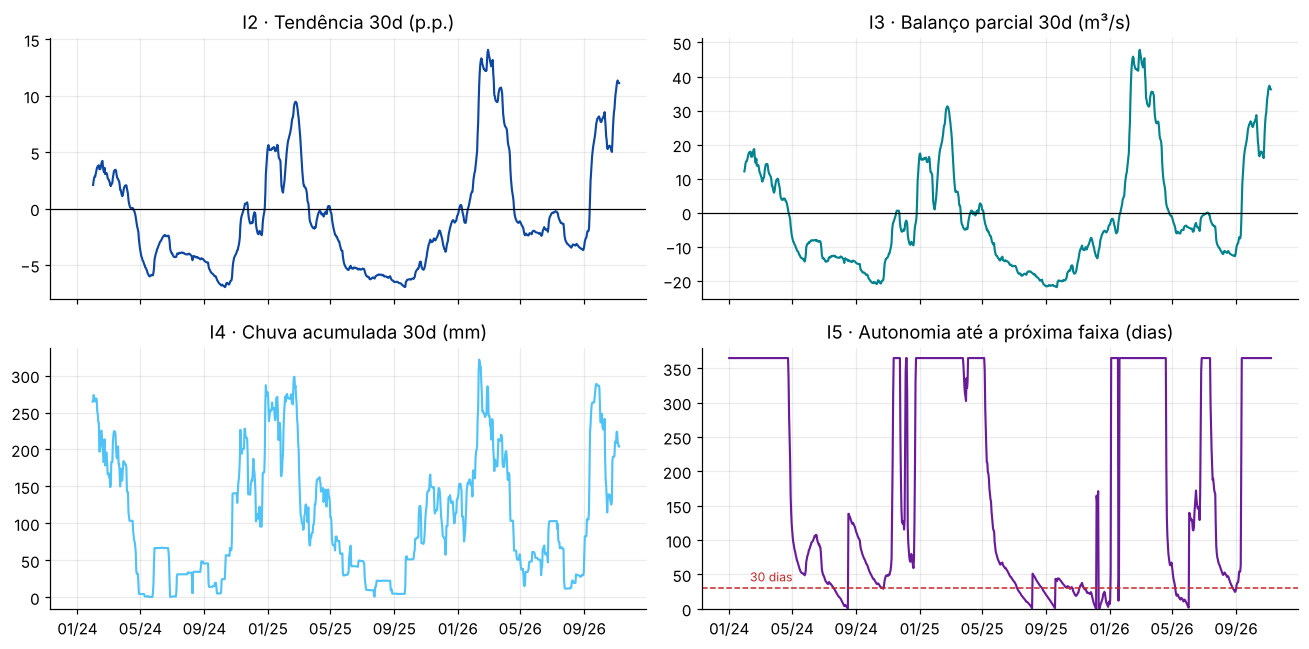

In [7]:
ult = ind.iloc[-1]
painel = pd.DataFrame({
    "valor em " + f"{ult.date:%d/%m/%Y}": [f"{ult.storage_pct:.2f} % (faixa {ult.faixa} · {hydro.nome_faixa(ult.faixa)})",
                                           f"{ult.trend_30d:+.2f} p.p.", f"{ult.balance_30d:+.1f} m³/s",
                                           f"{ult.rain_30d:.0f} mm",
                                           "sem queda" if ult.autonomia_dias >= 365 else f"{ult.autonomia_dias:.0f} dias"]},
    index=["I1 volume útil", "I2 tendência 30d", "I3 balanço parcial 30d", "I4 chuva 30d", "I5 autonomia"])
display(painel)

fig, axs = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for a, col, titulo, cor in [(axs[0, 0], "trend_30d", "I2 · Tendência 30d (p.p.)", "#0d47a1"),
                             (axs[0, 1], "balance_30d", "I3 · Balanço parcial 30d (m³/s)", "#00838f"),
                             (axs[1, 0], "rain_30d", "I4 · Chuva acumulada 30d (mm)", "#4fc3f7"),
                             (axs[1, 1], "autonomia_dias", "I5 · Autonomia até a próxima faixa (dias)", "#6a1b9a")]:
    a.plot(ind.date, ind[col], color=cor, lw=1.4); a.set_title(titulo)
axs[0, 0].axhline(0, color="k", lw=.8); axs[0, 1].axhline(0, color="k", lw=.8)
axs[1, 1].axhline(30, color="#c62828", ls="--", lw=1); axs[1, 1].text(ind.date.iloc[40], 40, "30 dias", color="#c62828", fontsize=8)
axs[1, 1].set_ylim(0, 380)
for a in axs[1]: a.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
fig.tight_layout(); plt.show()

**Interpretação.** O período tem seis mudanças para uma faixa mais restritiva: ago/2024 (→ 2), ago/2025 (→ 3), set/2025 (→ 4), dez/2025 (→ 5), jan/2026 (→ 5, após breve recuperação) e jun/2026 (→ 3). Em **todas** elas a autonomia (I5) ficou abaixo de 30 dias entre 24 e 29 dias **antes** da mudança, sempre com tendência e balanço parcial negativos. Em 07/11/2026 o quadro é o oposto: tendência e balanço positivos após as chuvas de outubro.

## 5. Modelagem

### 5.1 Desenho da avaliação

- **Validação temporal *walk-forward*:** sete janelas trimestrais de teste entre jan/2025 e set/2026. Cada modelo é treinado só com exemplos cujo **alvo** é anterior ao início da janela (purga do horizonte, sem vazamento) e testado na janela seguinte. Isso cobre a estiagem de 2025, a crise de dez/2025–jan/2026 e a recuperação de 2026, em vez de um único corte.
- **Atributos** (todos conhecidos em t): volume, tendências de 7 e 30 dias, chuva de 7/30/90 dias, afluência média de 7/30 dias, produção média de 30 dias, balanço parcial, distância até o limite da faixa e sazonalidade (seno/cosseno do dia do ano).
- **Referências simples:** persistência (o volume não muda) e extrapolação da tendência dos últimos 30 dias. Um modelo só tem valor se superar essas referências.

### 5.2 Regressão: variação do volume em 7 e 30 dias

Modelos: **Ridge** (linear regularizado, interpretável; α = 100 por causa da colinearidade entre atributos) e **Random Forest** (capta não linearidades, como o efeito de chuva forte). O alvo é a **variação** do volume, e não o nível: isso evita a falha de modelos de árvore que não extrapolam para níveis nunca vistos no treino — problema observado em uma primeira versão deste projeto.

In [8]:
FOLDS = hydro.walk_forward_folds("2025-01-01", "2026-09-30", months=3)
F_RIDGE = ["storage_pct", "trend_7d", "trend_30d", "rain_30d", "balance_30d", "doy_sin", "doy_cos"]

def modelos_regressao():
    return {
        "Ridge": (make_pipeline(StandardScaler(), Ridge(alpha=100)), F_RIDGE),
        "Random Forest": (RandomForestRegressor(n_estimators=300, min_samples_leaf=10, random_state=SEED, n_jobs=-1),
                          hydro.FEATURES),
    }

def avaliar_regressao(h):
    tabela = hydro.feature_table(df, h)
    linhas, previsoes = [], []
    for fold in FOLDS:
        treino, teste = hydro.split_fold(tabela, fold)
        p = {"Persistência": np.zeros(len(teste)), "Tendência 30d": teste.trend_30d.values * h / 30}
        for nome, (modelo, feats) in modelos_regressao().items():
            modelo.fit(treino[feats], treino.target_delta)
            p[nome] = modelo.predict(teste[feats])
        for nome, pred in p.items():
            linhas.append({"horizonte": h, "janela": fold.nome, "modelo": nome, "n": len(teste),
                           "MAE": mean_absolute_error(teste.target_delta, pred)})
            previsoes.append(pd.DataFrame({"date": teste.date.values, "alvo": teste.target_delta.values,
                                           "previsto": pred, "modelo": nome, "horizonte": h}))
    return pd.DataFrame(linhas), pd.concat(previsoes)

res7, prev7 = avaliar_regressao(7)
res30, prev30 = avaliar_regressao(30)
prev = pd.concat([prev7, prev30])
resumo_reg = (prev.assign(err=lambda d: d.previsto - d.alvo)
                  .groupby(["horizonte", "modelo"])
                  .agg(MAE=("err", lambda e: e.abs().mean()), RMSE=("err", lambda e: np.sqrt((e ** 2).mean())),
                       viés=("err", "mean"), n=("err", "size"))
                  .reset_index().sort_values(["horizonte", "MAE"]))
resumo_reg

,horizonte,modelo,MAE,RMSE,viés,n
2,7,Ridge,0.77,1.25,-0.15,638
3,7,Tendência 30d,0.80,1.28,0.01,638
1,7,Random Forest,0.94,1.40,-0.30,638
0,7,Persistência,1.10,1.51,0.10,638
7,30,Tendência 30d,3.22,4.72,-0.11,638
5,30,Random Forest,3.91,5.12,-2.51,638
6,30,Ridge,3.94,5.05,-1.13,638
4,30,Persistência,4.34,5.36,0.28,638


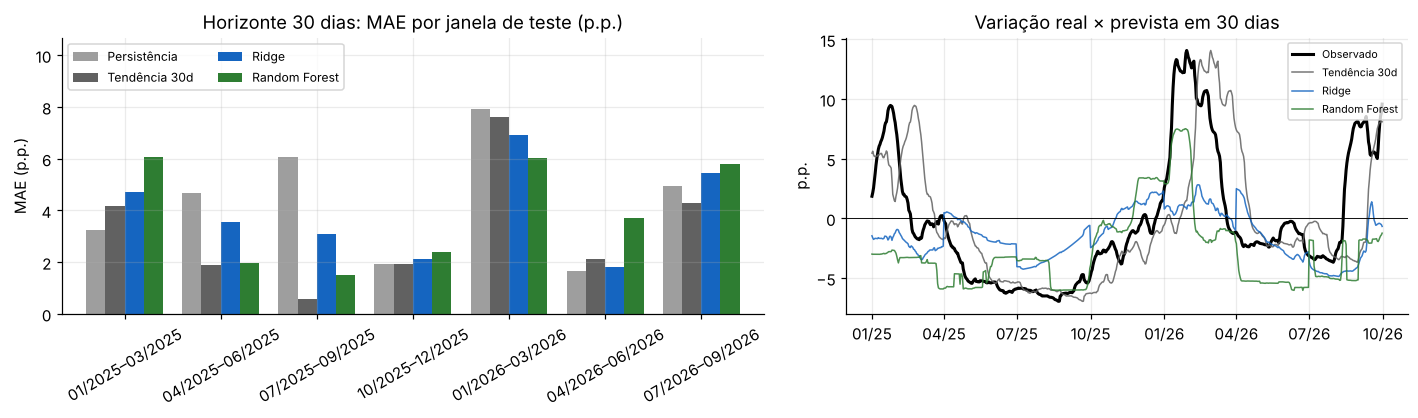

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.25, 1]})
piv = res30.pivot(index="janela", columns="modelo", values="MAE").loc[[f.nome for f in FOLDS]]
piv[["Persistência", "Tendência 30d", "Ridge", "Random Forest"]].plot.bar(
    ax=axs[0], color=["#9e9e9e", "#616161", "#1565c0", "#2e7d32"], width=0.8)
axs[0].set(title="Horizonte 30 dias: MAE por janela de teste (p.p.)", xlabel="", ylabel="MAE (p.p.)")
axs[0].tick_params(axis="x", rotation=30); axs[0].legend(fontsize=8, ncols=2, loc="upper left")
axs[0].set_ylim(0, piv.values.max() * 1.35)
p30 = prev30.pivot_table(index="date", columns="modelo", values="previsto")
alvo = prev30.drop_duplicates("date").set_index("date").alvo
axs[1].plot(alvo.index, alvo, color="k", lw=2, label="Observado")
for nome, cor in [("Tendência 30d", "#616161"), ("Ridge", "#1565c0"), ("Random Forest", "#2e7d32")]:
    axs[1].plot(p30.index, p30[nome], lw=1, color=cor, label=nome, alpha=.85)
axs[1].axhline(0, color="k", lw=.6)
axs[1].set(title="Variação real × prevista em 30 dias", ylabel="p.p.")
axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%y")); axs[1].legend(fontsize=7)
fig.tight_layout(); plt.show()

**Análise crítica da regressão.**
- Em **7 dias**, todos os erros são pequenos (abaixo de 1 p.p.). O Ridge teve o menor MAE (0,77 p.p.), praticamente empatado com a extrapolação de tendência (0,80 p.p.) — o reservatório tem muita inércia, e o ganho do modelo é marginal.
- Em **30 dias**, **nenhum modelo de aprendizado de máquina superou a extrapolação de tendência** no conjunto das janelas. Os maiores erros ocorrem no período chuvoso (jan–mar/2026 e out/2026), quando a variação depende de chuvas que ainda não aconteceram e não estão nos atributos. Na estiagem, os erros são baixos.
- Com menos de três anos de dados, há poucas estações chuvosas para aprender; o Ridge, em particular, produz erros grandes em algumas janelas porque extrapola relações lineares para fora do que viu.

**Consequência para o projeto:** não é responsável publicar uma previsão de volume para 30 dias como se fosse precisa. O volume previsto entra no alerta apenas com **intervalo de incerteza**, e a pergunta principal foi tratada como um problema de **classificação** — que depende de cruzar um limite, e não de acertar o valor exato.

### 5.3 Classificação: piora de faixa nos próximos 30 dias

Alvo: `1` se a faixa em t+30 for mais restritiva do que a faixa em t. Há 132 dias positivos em 923 (14 %), agrupados nas seis mudanças de faixa descritas na seção 4.

Modelos: **Regressão Logística** (pesos balanceados por classe; coeficientes interpretáveis) e **Random Forest** (pesos balanceados). Referência: **regra de autonomia** (alertar se I5 ≤ 30 dias).

**Escolha das métricas.** Deixar de avisar uma piora de faixa (falso negativo) custa mais do que um aviso preventivo que não se confirma (falso positivo): o primeiro deixa a gestão sem tempo de preparo; o segundo gera uma verificação extra. Por isso priorizamos **recall** e usamos **F2** (que pesa o recall duas vezes mais que a precisão), além de precisão e AUC. O limiar de probabilidade foi fixado em 0,5 antes da avaliação.

In [10]:
F_CLF = ["dist_next_threshold", "autonomia_dias", "trend_7d", "trend_30d", "rain_30d", "balance_30d", "doy_sin", "doy_cos"]
tab30 = hydro.feature_table(df, 30)

def modelos_classificacao():
    return {
        "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(C=0.5, class_weight="balanced", max_iter=2000)),
        "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced_subsample",
                                                random_state=SEED, n_jobs=-1),
    }

saidas = []
for fold in FOLDS:
    treino, teste = hydro.split_fold(tab30, fold)
    teste = teste.dropna(subset=["piora_faixa"])
    bloco = pd.DataFrame({"date": teste.date.values, "y": teste.piora_faixa.astype(int).values,
                          "Regra de autonomia": (teste.autonomia_dias <= 30).astype(float).values, "janela": fold.nome})
    for nome, modelo in modelos_classificacao().items():
        modelo.fit(treino[F_CLF], treino.piora_faixa.astype(int))
        bloco[nome] = modelo.predict_proba(teste[F_CLF])[:, 1]
    saidas.append(bloco)
clf = pd.concat(saidas, ignore_index=True)

LIMIAR = 0.5
linhas = []
for nome in ["Regra de autonomia", "Regressão Logística", "Random Forest"]:
    yhat = (clf[nome] >= LIMIAR).astype(int)
    linhas.append({"modelo": nome, "recall": recall_score(clf.y, yhat), "precisão": precision_score(clf.y, yhat),
                   "F2": fbeta_score(clf.y, yhat, beta=2),
                   "AUC": np.nan if nome.startswith("Regra") else roc_auc_score(clf.y, clf[nome]),
                   "falsos negativos": int(((yhat == 0) & (clf.y == 1)).sum()),
                   "falsos positivos": int(((yhat == 1) & (clf.y == 0)).sum())})
resumo_clf = pd.DataFrame(linhas).set_index("modelo")
print(f"Dias avaliados: {len(clf)} · positivos: {int(clf.y.sum())}")
resumo_clf

Dias avaliados: 638 · positivos: 102


,recall,precisão,F2,AUC,falsos negativos,falsos positivos
modelo,,,,,,
Regra de autonomia,0.86,0.59,0.79,NaN,14,61
Regressão Logística,0.85,0.61,0.79,0.93,15,56
Random Forest,0.38,0.78,0.43,0.90,63,11


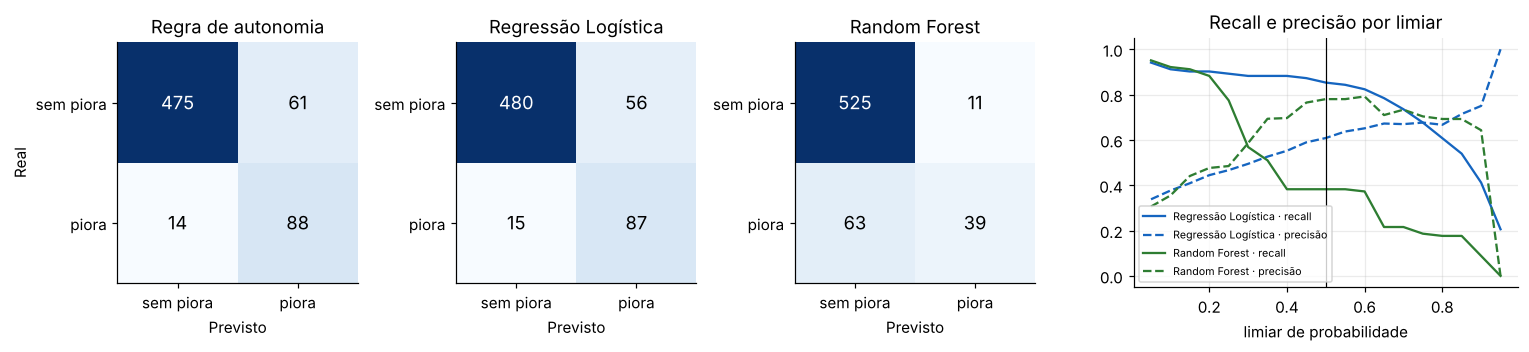

,coeficiente padronizado (modelo final)
dist_next_threshold,-4.42
trend_30d,-2.14
autonomia_dias,-1.99
balance_30d,-1.91
doy_cos,-1.16
rain_30d,-0.01
doy_sin,0.46
trend_7d,1.09


In [11]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.3), gridspec_kw={"width_ratios": [1, 1, 1, 1.6]})
for a, nome in zip(axs[:3], ["Regra de autonomia", "Regressão Logística", "Random Forest"]):
    cm = confusion_matrix(clf.y, (clf[nome] >= LIMIAR).astype(int))
    a.imshow(cm, cmap="Blues"); a.grid(False)
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=12, color="white" if cm[i, j] > cm.max() / 2 else "k")
    a.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["sem piora", "piora"], yticklabels=["sem piora", "piora"],
          title=nome, xlabel="Previsto", ylabel="Real" if a is axs[0] else "")
limiares = np.linspace(0.05, 0.95, 19)
for nome, cor in [("Regressão Logística", "#1565c0"), ("Random Forest", "#2e7d32")]:
    axs[3].plot(limiares, [recall_score(clf.y, clf[nome] >= l) for l in limiares], color=cor, label=f"{nome} · recall")
    axs[3].plot(limiares, [precision_score(clf.y, clf[nome] >= l, zero_division=0) for l in limiares], color=cor, ls="--",
                label=f"{nome} · precisão")
axs[3].axvline(LIMIAR, color="k", lw=.8); axs[3].set(title="Recall e precisão por limiar", xlabel="limiar de probabilidade")
axs[3].legend(fontsize=7)
fig.tight_layout(); plt.show()

coef = modelos_classificacao()["Regressão Logística"].fit(tab30.dropna(subset=["piora_faixa"])[F_CLF],
                                                           tab30.dropna(subset=["piora_faixa"]).piora_faixa.astype(int))
pd.Series(coef[-1].coef_[0], index=F_CLF).sort_values().rename("coeficiente padronizado (modelo final)").to_frame()

**Análise crítica da classificação.**
- A **Regressão Logística** foi o melhor modelo: recall próximo ao da regra de autonomia, com precisão um pouco maior e AUC acima de 0,9. Os coeficientes mais fortes fazem sentido físico: distância pequena até o limite da faixa, tendência de 30 dias negativa, autonomia curta e balanço negativo aumentam a probabilidade de piora. A chuva de 30 dias ficou com peso quase nulo porque seu efeito já está no balanço; o sinal positivo da tendência de 7 dias vem da colinearidade com a de 30 dias e não deve ser interpretado isoladamente.
- O **Random Forest** teve recall bem menor no limiar 0,5. Com apenas seis mudanças de faixa no período e poucos exemplos positivos nas primeiras janelas, as árvores ficam conservadoras; um modelo linear sobre atributos bem construídos generaliza melhor com pouca informação.
- A regra simples de autonomia é uma referência forte, o que é uma boa notícia para a gestão: o sinal é explicável e auditável. O modelo acrescenta uma **probabilidade**, útil para ordenar a prioridade de avaliação.
- **Erros que importam:** os 15 falsos negativos da Regressão Logística ocorreram (a) no começo de episódios, quando faltavam 34–43 dias para a mudança — o aviso veio alguns dias depois do ideal — e (b) em dez/2025, quando uma chuva elevou o volume para pouco acima de 20 % e o sistema voltou a cair em seguida. A maioria dos falsos positivos (43 de 56) está em ago–set/2026, quando a queda em direção a 30 % foi interrompida pelas chuvas fortes de setembro — um aviso preventivo aceitável.

## 6. Critérios de alerta e situação atual

O nível de alerta combina a faixa oficial com a antecipação do modelo:

| Situação | Nível |
|---|---|
| Faixa 1 (≥ 60 %) sem sinal de piora | **Normal** |
| Faixa 2 (40–60 %), ou Faixa 1 com sinal de piora em 30 dias | **Atenção** |
| Faixa 3 (30–40 %), ou Faixa 2 com sinal de piora | **Alerta** |
| Faixas 4–5 (< 30 %), ou Faixa 3 com sinal de piora | **Crítico** |

**Sinal de piora** = probabilidade da Regressão Logística ≥ 0,5 **ou** autonomia ≤ 30 dias (as duas fontes são exibidas para quem decide). O nível é uma recomendação para **avaliação humana**; ele não confirma uma crise nem autoriza restrição no abastecimento. Observação: oficialmente, a faixa de cada mês é definida pelo volume do último dia do mês anterior; o indicador diário serve como aviso antecipado.

nivel
Atenção    471
Crítico    221
Alerta     168
Normal     152


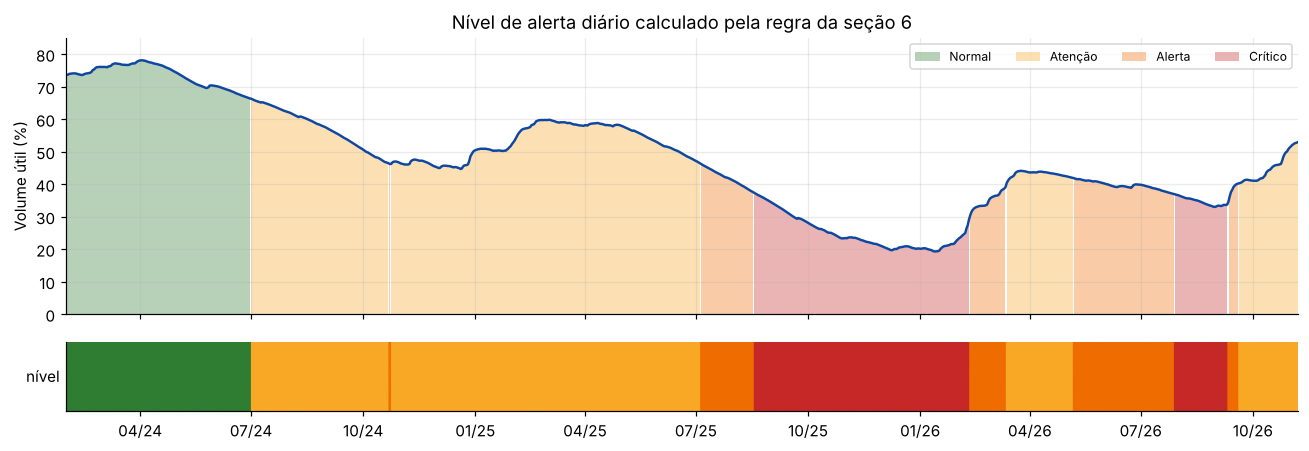

In [12]:
# Modelo final: treinado com todos os exemplos rotulados (alvos até 07/11/2026)
rot = tab30.dropna(subset=["piora_faixa"])
final = modelos_classificacao()["Regressão Logística"].fit(rot[F_CLF], rot.piora_faixa.astype(int))
hist = ind.dropna(subset=F_CLF).copy()
hist["prob_piora"] = final.predict_proba(hist[F_CLF])[:, 1]  # dentro da amostra: uso ilustrativo
# para o histórico usamos as probabilidades fora da amostra do walk-forward quando existem
oos = clf.set_index("date")["Regressão Logística"]
hist["prob_piora"] = hist.date.map(oos).fillna(hist.prob_piora)
hist["sinal"] = (hist.prob_piora >= LIMIAR) | (hist.autonomia_dias <= 30)
hist["nivel"] = [hydro.nivel_alerta(f, f + 1 if s else f) for f, s in zip(hist.faixa, hist.sinal)]

from matplotlib.colors import ListedColormap
fig, (ax, faixa_ax) = plt.subplots(2, 1, figsize=(12, 4.2), sharex=True, height_ratios=[4, 1])
ax.plot(hist.date, hist.storage_pct, color="#0d47a1", lw=1.6)
for n, nome in enumerate(hydro.NIVEIS):
    ax.fill_between(hist.date, 0, hist.storage_pct, where=hist.nivel == n, color=CORES_NIVEL[n], alpha=0.35,
                    step="mid", label=nome, lw=0)
ax.set(title="Nível de alerta diário calculado pela regra da seção 6", ylabel="Volume útil (%)", ylim=(0, 85))
ax.legend(ncols=4, fontsize=8, loc="upper right")
num = mdates.date2num(hist.date)
faixa_ax.imshow(hist.nivel.values[None, :], aspect="auto", cmap=ListedColormap(CORES_NIVEL), vmin=0, vmax=3,
                extent=[num[0], num[-1], 0, 1])
faixa_ax.set_yticks([]); faixa_ax.grid(False); faixa_ax.set_ylabel("nível", rotation=0, ha="right", va="center")
faixa_ax.xaxis_date(); faixa_ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
fig.tight_layout(); plt.show()
print(hist.nivel.map(dict(enumerate(hydro.NIVEIS))).value_counts().to_string())

In [13]:
# Situação em 07/11/2026 e projeção de 30 dias com incerteza empírica (erros fora da amostra da regra de tendência)
atual = hist.iloc[-1]
erros_tend = prev30.query("modelo == 'Tendência 30d'").pipe(lambda d: d.previsto - d.alvo)
q10, q90 = np.quantile(-erros_tend, [0.10, 0.90])
proj = atual.storage_pct + atual.trend_30d
faixa_proj = hydro.faixa(float(np.clip(proj, 0, 100)))
nivel_atual = hydro.NIVEIS[int(atual.nivel)]
situacao = {
    "data de referência": f"{atual.date:%d/%m/%Y}",
    "volume útil": f"{atual.storage_pct:.2f} %",
    "faixa de operação": f"{int(atual.faixa)} · {hydro.nome_faixa(int(atual.faixa))}",
    "tendência 30 dias": f"{atual.trend_30d:+.2f} p.p.",
    "balanço parcial 30 dias": f"{atual.balance_30d:+.1f} m³/s",
    "probabilidade de piora de faixa (30 dias)": f"{atual.prob_piora:.0%}",
    "projeção de volume em 30 dias (tendência)": f"{proj:.1f} % (intervalo 80 %: {proj + q10:.1f} a {min(proj + q90, 100):.1f} %)",
    "NÍVEL DE ALERTA": nivel_atual,
}
display(pd.Series(situacao, name="Cantareira").to_frame())
print(f"Explicação: o sistema está na faixa {int(atual.faixa)} ({hydro.nome_faixa(int(atual.faixa))}), com tendência "
      f"{'de alta' if atual.trend_30d > 0 else 'de queda'} e balanço {'positivo' if atual.balance_30d > 0 else 'negativo'}. "
      f"Não há sinal de piora de faixa nos próximos 30 dias; o nível {nivel_atual} decorre da faixa atual. "
      "A projeção tem incerteza alta na estação chuvosa e não deve ser lida como garantia de retorno à faixa Normal.")

Explicação: o sistema está na faixa 2 (Atenção), com tendência de alta e balanço positivo. Não há sinal de piora de faixa nos próximos 30 dias; o nível Atenção decorre da faixa atual. A projeção tem incerteza alta na estação chuvosa e não deve ser lida como garantia de retorno à faixa Normal.


,Cantareira
data de referência,07/11/2026
volume útil,52.94 %
faixa de operação,2 · Atenção
tendência 30 dias,+11.12 p.p.
balanço parcial 30 dias,+36.2 m³/s
probabilidade de piora de faixa (30 dias),0%
projeção de volume em 30 dias (tendência),64.1 % (intervalo 80 %: 58.6 a 69.9 %)
NÍVEL DE ALERTA,Atenção


## 7. Conclusões e recomendações

**Resposta à pergunta de pesquisa.** Sim: com dados públicos diários, é possível sinalizar com até 30 dias de antecedência a entrada do Cantareira em uma faixa mais restritiva. Na validação *walk-forward* (jan/2025–set/2026), a Regressão Logística e a regra de autonomia identificaram cerca de 85 % dos dias que antecederam pioras de faixa. O sinal depende principalmente de três evidências que a gestão pode verificar: distância até o limite da faixa, tendência de queda e balanço hídrico negativo.

**O que os dados não permitem:** prever com precisão o volume daqui a 30 dias na estação chuvosa. Modelos de ML não superaram a extrapolação de tendência nesse horizonte; o volume futuro depende de chuva ainda não observada.

**Situação em 07/11/2026:** faixa 2 (Atenção), com tendência e balanço positivos após as chuvas de outubro. A recomendação é manter o acompanhamento normal da faixa de Atenção, sem sinal de piora no curto prazo.

**Recomendações para a gestão (sujeitas à avaliação dos responsáveis):**
1. **Usar o volume no fim de março como indicador-chave do ano.** Como o sistema consome estoque de abril a novembro, um volume baixo em março antecipa risco no segundo semestre; esse é o momento de avaliar medidas preventivas.
2. **Acompanhar semanalmente a autonomia (I5) a partir de abril**, com atenção redobrada quando ficar abaixo de 60 dias; abaixo de 30 dias, preparar a comunicação e os planos de contingência da faixa seguinte.
3. **Incorporar previsão meteorológica sazonal e a vazão de jusante** antes de qualquer previsão de volume para 30 dias ou mais.
4. **Ampliar para os demais sistemas produtores (Alto Tietê, Guarapiranga etc.)**, já que o risco da RMSP depende da integração entre eles.

## 8. Limitações, responsabilidade e reprodutibilidade

- **Cobertura:** um sistema, menos de três anos e seis mudanças de faixa — as métricas têm incerteza amostral relevante.
- **Variáveis ausentes:** vazão de jusante, evaporação, transferências entre sistemas e previsão de chuva.
- **Fonte:** endpoint não documentado; os arquivos mensais brutos ficam no repositório para auditoria. A licença de redistribuição não foi localizada — uso acadêmico com atribuição.
- **Vieses:** o período inclui uma das piores estiagens da década; outro período pode gerar coeficientes diferentes.
- **Supervisão humana:** o alerta organiza evidências; decisões de restrição ou racionamento são exclusivas dos gestores competentes.
- **Privacidade:** não há dados pessoais.
- **Reprodutibilidade:** semente fixa (42), dados versionados, funções testadas em `tests/`; basta executar o notebook do início ao fim.
- **Uso de IA generativa:** ferramenta de apoio (dúvidas, sugestões de código, depuração e revisão de textos); métricas e interpretações conferidas pela dupla nos resultados executados.

In [14]:
# Exporta os números usados na síntese executiva
resultados = {
    "periodo": [f"{df.date.min():%d/%m/%Y}", f"{df.date.max():%d/%m/%Y}"], "dias": len(df),
    "situacao_atual": situacao,
    "regressao": resumo_reg.round(3).to_dict(orient="records"),
    "classificacao": resumo_clf.round(3).reset_index().to_dict(orient="records"),
    "dias_por_nivel": hist.nivel.map(dict(enumerate(hydro.NIVEIS))).value_counts().to_dict(),
}
(ROOT / "reports").mkdir(exist_ok=True)
(ROOT / "reports" / "results.json").write_text(json.dumps(resultados, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("reports/results.json atualizado")

reports/results.json atualizado
